In [113]:
import numpy as np
import matplotlib.pyplot as plt

(i) First we construct the memory and fix it

In [114]:
N = 400
P = 40

rng = np.random.default_rng()
memory = rng.choice([-1,1], size=(P, N))

(ii) Build the interaction matrix corresponding to the memory accroding to eq (1)

In [119]:
J = np.zeros([N,N])

for i in range(N):
    for j in range(i+1, N):
        J[i, j] = np.sum(memory[:,i]*memory[:,j],axis=0)/N
        J[j, i] = J[i, j]

(iii) Deterministoc dynamics following from eq (2) and (3)

In [97]:
def next_step(old, J):

    h = np.einsum('ij, j->i', J, old)

    new = np.sign(h)
    h0 = np.where(h==0)
    new[h0] = old[h0]

    return new

(iv) function to generate starting state which deviates from memory 1 by some fraction

In [120]:
def generate_start(frac):
    M = int(frac*N)
    indices = rng.choice(np.arange(N), size=M, replace=False)
    start = memory[0].copy()
    start[indices]*=-1

    return start

(v) Check to see if we can go back to the memory we started from in 30 steps

In [134]:
m = np.zeros([3, 30])
fracs = [0.05, 0.25, 0.40]
starts = np.array([generate_start(fracs[0]), generate_start(fracs[1]), generate_start(fracs[2])])

for i in range(30):
    # define the overalp
    m[0, i] = np.sum(memory[0]*starts[0])/N
    m[1, i] = np.sum(memory[0]*starts[1])/N
    m[2, i] = np.sum(memory[0]*starts[2])/N
    starts[0] = next_step(starts[0], J)
    starts[1] = next_step(starts[1], J)
    starts[2] = next_step(starts[2], J)

(vi) Plotting

+++ Check [m1(0)=1-2f] +++
f=0.05: True
f=0.25: True
f=0.4: True


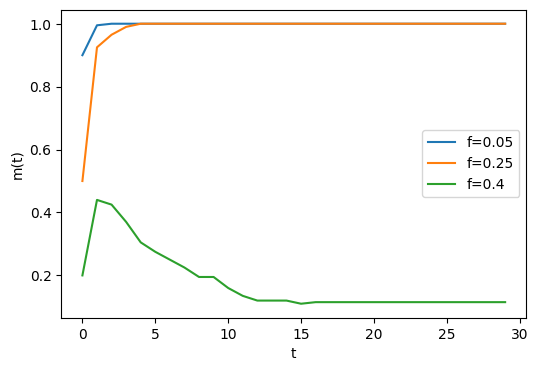

In [141]:
fig, ax = plt.subplots(1,1,figsize=(6, 4))
ax.set_xlabel('t')
ax.set_ylabel('m(t)')

print('+++ Check [m1(0)=1-2f] +++')

for i in range(len(fracs)):
    print(f'f={fracs[i]}: {np.allclose(m[i,0],1-2*fracs[i])}')
    ax.plot(m[i], label=f'f={fracs[i]}')

ax.legend();

So for lower fractions we end up in the same memory we started close too, but not for higher starting deviations